# Dynamic Pricing for Urban Parking Lots

A walkthrough of the pricing engine: **data → features → three pricing models → real-time
stream with Pathway → live visualisation**. All the logic lives in the `parking_pricing`
package; this notebook drives it and explains the decisions.

| Model | Idea |
|---|---|
| 1 - Baseline linear | price drifts with occupancy vs. a target, resets daily |
| 2 - Demand based | weighted demand score (occupancy, queue, traffic, special day, vehicle, trend), normalised and smoothed |
| 3 - Competitive | nudges Model 2 toward nearby lots; full lots reroute drivers instead of cutting price |

> **Colab:** run the next cell to fetch the repo and install dependencies. Pathway runs on
> Linux/macOS (Colab is fine); on Windows use Docker - the Pathway section skips itself.

In [1]:
import importlib.util, os, subprocess, sys

if "google.colab" in sys.modules and not os.path.exists("parking_pricing"):
    subprocess.run(["git", "clone", "https://github.com/Aniruddha-Ray/Dynamic-Pricing-for-Urban-Parking-Lots.git"], check=True)
    os.chdir("Dynamic-Pricing-for-Urban-Parking-Lots")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", ".[all]"], check=True)

PATHWAY_OK = importlib.util.find_spec("pathway") is not None and sys.platform != "win32"
print("Pathway available:", PATHWAY_OK)

Pathway available: True


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from parking_pricing import metrics, models
from parking_pricing.config import DEFAULT_CONFIG as cfg
from parking_pricing.data import clean, load_raw, lot_registry
from parking_pricing.replay import run_replay

pd.set_option("display.width", 140)
pd.set_option("display.float_format", "{:,.3f}".format)

# one colour per model (validated categorical slots), used in every chart below
COLORS = {"price_baseline": "#2a78d6", "price_demand": "#eb6834", "price_competitive": "#1baf7a"}
LABELS = {"price_baseline": "Model 1 - baseline", "price_demand": "Model 2 - demand",
          "price_competitive": "Model 3 - competitive"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e1", "axes.axisbelow": True,
                     "axes.edgecolor": "#c3c2b7", "figure.dpi": 110})

## 1. Load and clean the data

The raw feed has a few problems the original hackathon notebook silently ignored. The cleaning
step fixes and reports them:

* **duplicate readings** - some sensors logged several events in the same minute (same occupancy,
  different vehicle type); we keep one per lot per timestamp,
* **occupancy above capacity** - occupancy rate is clipped to 100 %,
* **bad coordinates** - one lot is geocoded to the centre of India (~1,500 km away); it is priced
  normally but excluded from the competition model.

In [3]:
raw = load_raw()
df, report = clean(raw)
print(report)
df.head()

rows=18,282  lots=14  days=73  span=2016-10-04 -> 2016-12-19
occupancy > capacity: 241 rows (rate clipped to 1.0)
duplicate (lot, timestamp) readings collapsed: 86
dropped (unparseable/invalid): 0 rows
unknown traffic labels: 0, unknown vehicle types: 0
lots with invalid coordinates (excluded from competition): ['BHMMBMMBX01']


,timestamp,lot_id,capacity,occupancy,queue_length,traffic,vehicle_type,is_special_day,latitude,longitude
0,2016-10-04 07:59:00,BHMBCCMKT01,577,61,1,low,car,0,26.145,91.736
1,2016-10-04 07:59:00,BHMBCCTHL01,387,120,2,low,car,0,26.144,91.736
2,2016-10-04 07:59:00,BHMEURBRD01,470,117,2,low,car,0,26.149,91.740
3,2016-10-04 07:59:00,BHMMBMMBX01,687,264,2,low,car,0,20.000,78.000
4,2016-10-04 07:59:00,BHMNCPHST01,1200,237,2,low,bike,0,26.140,91.731


In [4]:
lots = lot_registry(df)
lots

,capacity,latitude,longitude,valid_coords
lot_id,,,,
BHMBCCMKT01,577,26.145,91.736,True
BHMBCCTHL01,387,26.144,91.736,True
BHMEURBRD01,470,26.149,91.740,True
BHMMBMMBX01,687,20.000,78.000,False
BHMNCPHST01,1200,26.140,91.731,True
BHMNCPNST01,485,26.140,91.731,True
Broad Street,690,26.138,91.741,True
Others-CCCPS105a,2009,26.147,91.728,True
Others-CCCPS119a,2803,26.148,91.728,True


## 2. Exploring demand

Every lot reports roughly every 30 minutes between 08:00 and 16:30. Occupancy has a strong
intraday shape and lots differ a lot in how busy they get, which is exactly why a single
city-wide daily price (what the first version computed) is not enough.

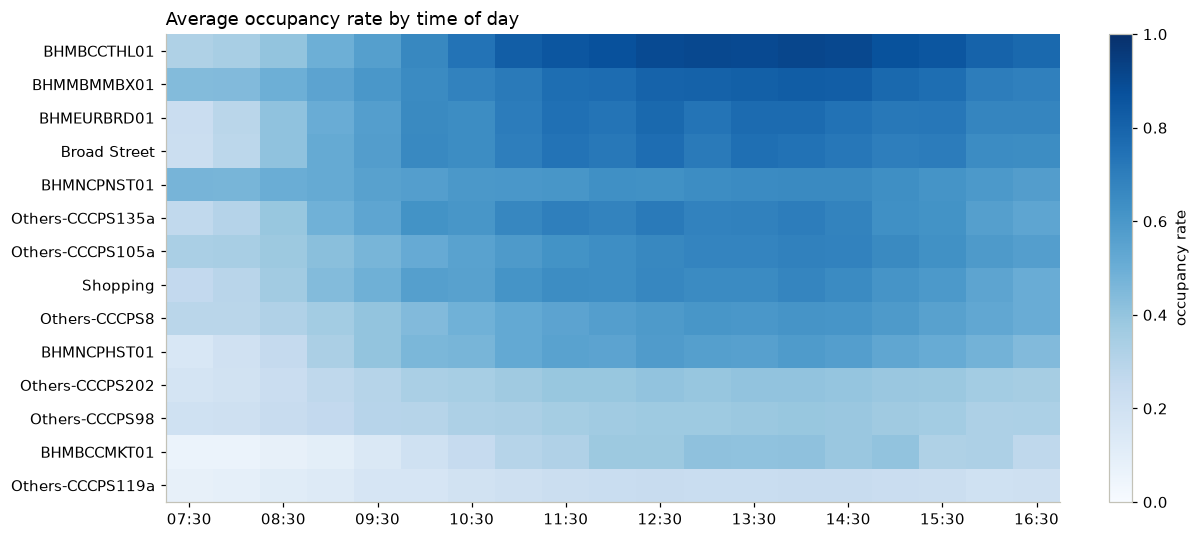

In [5]:
df["occ_rate"] = (df["occupancy"] / df["capacity"]).clip(upper=1)
df["slot"] = df["timestamp"].dt.floor("30min").dt.strftime("%H:%M")
profile = df.pivot_table(index="lot_id", columns="slot", values="occ_rate", aggfunc="mean")
profile = profile.loc[profile.mean(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(11, 5))
im = ax.imshow(profile.values, aspect="auto", cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(0, profile.shape[1], 2), profile.columns[::2])
ax.set_yticks(range(len(profile)), profile.index)
ax.grid(False)
ax.set_title("Average occupancy rate by time of day", loc="left")
fig.colorbar(im, ax=ax, label="occupancy rate", fraction=0.03)
plt.tight_layout()

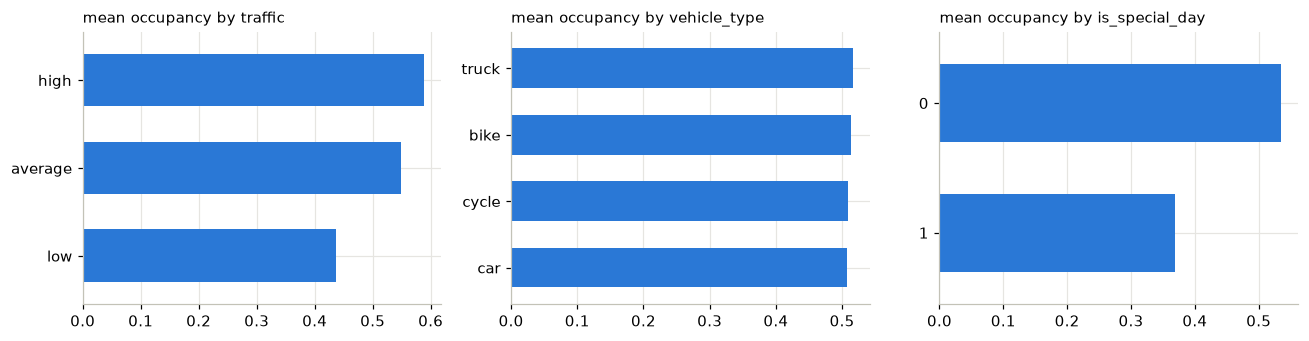

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, col in zip(axes, ["traffic", "vehicle_type", "is_special_day"]):
    df.groupby(col)["occ_rate"].mean().sort_values().plot.barh(ax=ax, color="#2a78d6", width=0.6)
    ax.set_title(f"mean occupancy by {col}", loc="left", fontsize=10)
    ax.set_ylabel("")
plt.tight_layout()

## 3. The three models

All parameters live in one `PricingConfig`; prices are always bounded to
`[0.5x, 2.0x]` the base price of $10.

**Model 1 - baseline linear.** `p_t = clip(p_(t-1) + alpha * (occupancy_rate - target))`, reset to the
base price each morning. Simple and explainable, but it only knows about occupancy and accumulates
error over the day.

**Model 2 - demand based.** Each driver is normalised to [0, 1] before weighting (the original
version used the raw queue length, so a queue of 10 cars outweighed everything else):

```
demand  = 0.55*occupancy + 0.20*queue - 0.10*traffic + 0.10*special_day + 0.05*vehicle + 0.10*trend
d_norm  = (demand - demand_min) / (demand_max - demand_min)            # in [0, 1]
raw     = base * (1 + lambda * (d_norm - d_neutral))                    # d_neutral -> exactly $10
price_t = clip(0.5 * raw + 0.5 * price_(t-1))                           # EMA smoothing
```

Heavy nearby traffic *lowers* the price (the lot is harder to reach), `trend` is the change in
occupancy since the previous reading.

**Model 3 - competitive.** For lots within 1 km, take the distance-weighted average of their
Model 2 prices and close 30 % of the gap. A lot that is >= 90 % full never undercuts; it holds its
price and suggests rerouting to the neighbour with space that is cheapest once a $2/km travel
penalty is added (so a lot next door beats a slightly cheaper one across town).

In [7]:
print(cfg)
print("neutral normalised demand:", round(models.neutral_demand(cfg), 3))

PricingConfig(base_price=10.0, min_multiplier=0.5, max_multiplier=2.0, baseline_alpha=1.0, target_occupancy=0.6, w_occupancy=0.55, w_queue=0.2, w_traffic=0.1, w_special=0.1, w_vehicle=0.05, w_trend=0.1, demand_lambda=1.5, smoothing=0.5, neutral_occupancy=0.6, neutral_queue=0.3, neutral_traffic=0.5, neutral_vehicle=0.7, neighbor_radius_km=1.0, competition_kappa=0.3, full_threshold=0.9, reroute_cost_per_km=2.0, queue_saturation=10, trend_saturation=0.25, traffic_levels={'low': 0.0, 'average': 0.5, 'high': 1.0}, vehicle_weights={'cycle': 0.2, 'bike': 0.4, 'car': 0.7, 'truck': 1.0})
neutral normalised demand: 0.479


## 4. Replay the season through the engine

`run_replay` feeds the readings to the stateful `PricingEngine` one timestamp at a time - the
same object the REST API uses for live readings.

In [8]:
%time priced = run_replay(df.drop(columns=["occ_rate", "slot"]), cfg)
priced.head()

CPU times: user 2.95 s, sys: 54.5 ms, total: 3.01 s
Wall time: 3.01 s


,timestamp,lot_id,capacity,occupancy,queue_length,traffic,vehicle_type,is_special_day,latitude,longitude,occupancy_rate,demand,price_baseline,price_demand,price_competitive,competitor_price,action,reroute_to
0,2016-10-04 07:59:00,BHMBCCMKT01,577,61,1,low,car,0,26.145,91.736,0.106,0.261,9.506,6.727,7.167,8.193,raise,NaN
1,2016-10-04 07:59:00,BHMBCCTHL01,387,120,2,low,car,0,26.144,91.736,0.310,0.371,9.710,8.382,8.037,7.232,lower,NaN
2,2016-10-04 07:59:00,BHMEURBRD01,470,117,2,low,car,0,26.149,91.740,0.249,0.343,9.649,7.961,7.896,7.744,lower,NaN
3,2016-10-04 07:59:00,BHMMBMMBX01,687,264,2,low,car,0,20.000,78.000,0.384,0.405,9.784,8.892,8.892,NaN,no_competitors,NaN
4,2016-10-04 07:59:00,BHMNCPHST01,1200,237,2,low,bike,0,26.140,91.731,0.198,0.307,9.598,7.420,7.911,9.056,raise,NaN


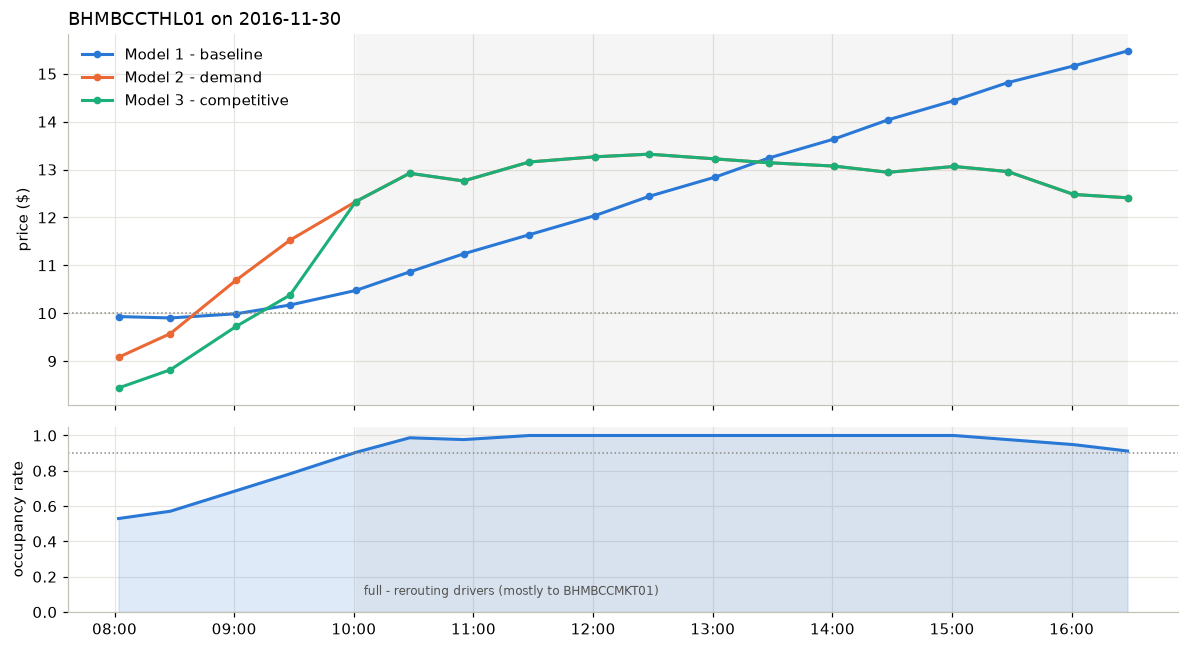

In [9]:
def plot_lot_day(lot, day):
    sel = priced[(priced["lot_id"] == lot) & (priced["timestamp"].dt.date == pd.Timestamp(day).date())]
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True,
                                   gridspec_kw={"height_ratios": [2, 1]})
    for col, color in COLORS.items():
        ax1.plot(sel["timestamp"], sel[col], color=color, lw=2, marker="o", ms=4, label=LABELS[col])
    ax1.axhline(cfg.base_price, color="#8a8984", lw=1, ls=":")
    ax1.set_ylabel("price ($)")
    ax1.legend(loc="upper left", frameon=False)
    ax1.set_title(f"{lot} on {day}", loc="left")
    ax2.fill_between(sel["timestamp"], sel["occupancy_rate"], color="#2a78d6", alpha=0.15)
    ax2.plot(sel["timestamp"], sel["occupancy_rate"], color="#2a78d6", lw=2)
    ax2.axhline(cfg.full_threshold, color="#8a8984", lw=1, ls=":")
    ax2.set_ylim(0, 1.05)
    ax2.set_ylabel("occupancy rate")
    reroutes = sel[sel["reroute_to"].notna()]
    if len(reroutes):
        start, end = reroutes["timestamp"].min(), reroutes["timestamp"].max()
        for ax in (ax1, ax2):
            ax.axvspan(start, end, color="#8a8984", alpha=0.08, lw=0)
        target = reroutes["reroute_to"].mode()[0]
        ax2.text(start, 0.08, f"  full - rerouting drivers (mostly to {target})",
                 fontsize=8, color="#52514e", va="bottom")
    ax2.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%H:%M"))
    plt.tight_layout()

plot_lot_day("BHMBCCTHL01", "2016-11-30")

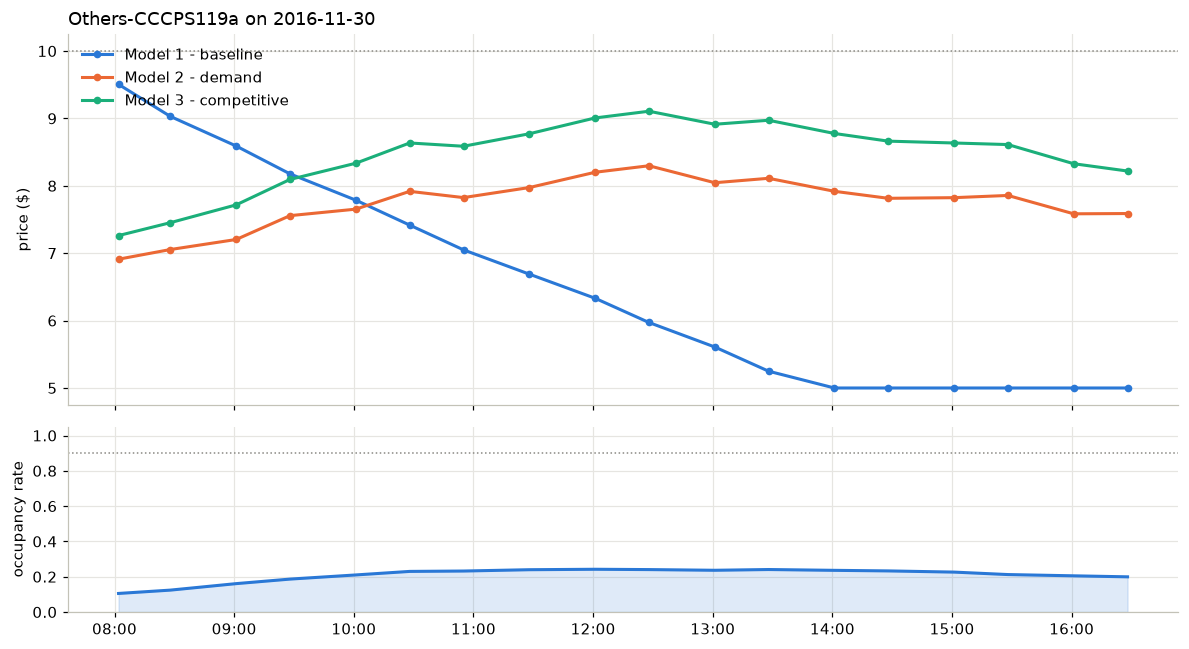

In [10]:
plot_lot_day("Others-CCCPS119a", "2016-11-30")

What the two days show:

* **Busy lot (BHMBCCTHL01).** Model 2 rises with demand as the lot fills. Below 90 % Model 3 sits
  under Model 2, because the neighbours are cheaper. From 10:00 the lot is full: Model 3 stops
  undercutting (it equals Model 2) and every reading carries a reroute suggestion, mostly to
  BHMBCCMKT01, the half-empty lot about 10 m away.
* **Quiet lot (Others-CCCPS119a).** Model 2 offers a discount. Model 3 takes part of it back
  because the neighbours are pricier, so the lot can charge a bit more and still be the cheapest
  option nearby.
* **Model 1's weakness** is visible in both: it only accumulates `occupancy - target`, so it keeps
  climbing after the busy lot's peak and slides to the $5 floor at the quiet lot by early afternoon.

## 5. Comparing the models

There is no ground-truth price, so the models are compared on behaviour. The revenue index is a
static proxy (it assumes demand does not react to price) - it shows how well prices line up with
busy periods, not a revenue forecast.

In [11]:
metrics.model_summary(priced, cfg)

,mean_price,std_price,min_price,max_price,corr_with_occupancy,mean_abs_step,pct_at_bounds,revenue_index
model,,,,,,,,
Model 1 - baseline,8.805,2.087,5.000,15.784,0.702,0.189,7.264,0.904
Model 2 - demand,9.997,1.729,5.354,15.133,0.937,0.265,0.000,1.046
Model 3 - competitive,9.989,1.480,6.085,15.133,0.894,0.260,0.000,1.030


In [12]:
metrics.lot_summary(priced)

,mean_occupancy,pct_full,m1_mean,m2_mean,m3_mean,reroutes
lot_id,,,,,,
BHMBCCTHL01,0.742,26.167,10.549,11.449,10.973,342
BHMMBMMBX01,0.696,11.783,10.418,11.250,11.250,0
BHMEURBRD01,0.646,24.962,9.940,10.786,10.711,326
Broad Street,0.634,23.813,9.908,10.764,10.663,311
Others-CCCPS135a,0.592,0.306,9.579,10.782,10.333,4
BHMNCPNST01,0.591,0.539,9.688,10.450,10.216,7
Others-CCCPS105a,0.568,0.383,9.230,10.518,10.171,5
Shopping,0.557,0.000,9.226,10.440,10.221,0
Others-CCCPS8,0.501,0.306,8.613,9.975,9.806,4


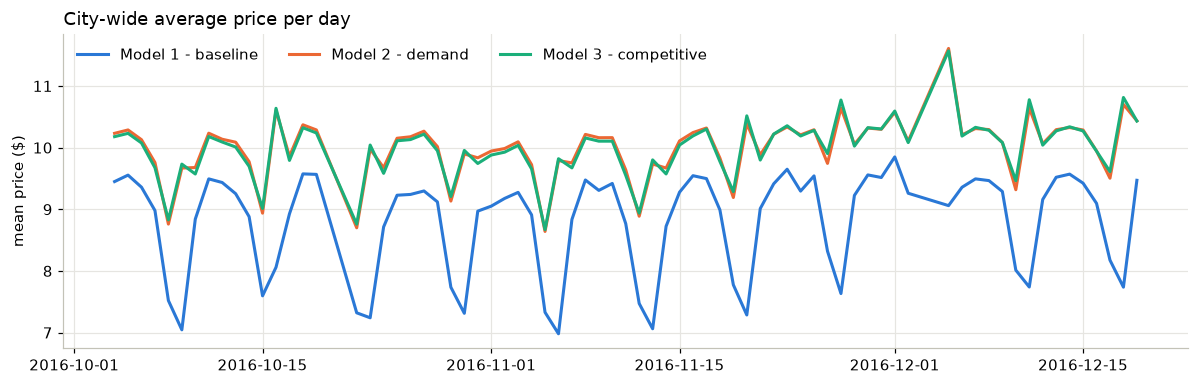

In [13]:
daily = (priced.assign(day=priced["timestamp"].dt.normalize())
               .groupby("day")[list(COLORS)].mean())
fig, ax = plt.subplots(figsize=(11, 3.6))
for col, color in COLORS.items():
    ax.plot(daily.index, daily[col], color=color, lw=2, label=LABELS[col])
ax.set_ylabel("mean price ($)")
ax.set_title("City-wide average price per day", loc="left")
ax.legend(loc="upper left", frameon=False, ncol=3)
plt.tight_layout()

In [14]:
print("Model 3 decisions (% of readings)")
print(metrics.action_breakdown(priced).to_string())
(priced.dropna(subset=["reroute_to"])
       .groupby(["lot_id", "reroute_to"]).size().sort_values(ascending=False).head(8)
       .rename("reroutes").to_frame())

Model 3 decisions (% of readings)
action
lower            46.200
raise            41.100
no_competitors    7.200
reroute           5.500


reroutes
lot_id           reroute_to                
BHMEURBRD01      BHMBCCMKT01            326
Broad Street     BHMBCCMKT01            311
BHMBCCTHL01      BHMBCCMKT01            276
                 Others-CCCPS119a        31
                 BHMEURBRD01             29
BHMNCPNST01      Others-CCCPS119a         7
Others-CCCPS105a Others-CCCPS119a         5
BHMBCCMKT01      Others-CCCPS119a         5

## 6. Real-time pipeline with Pathway

The same models run inside a Pathway dataflow (`parking_pricing/pathway_pipeline.py`):

* `pw.demo.replay_csv` streams the readings at a fixed rate, simulating live sensors,
* readings are grouped per **lot and day**; a UDF runs Models 1 & 2 over the lot's history, so
  every new reading updates that lot's price,
* a join with the static neighbour table feeds Model 3,
* a tumbling **1-day window** per lot produces daily occupancy KPIs,
* `table.plot(...)` renders a live Bokeh chart that updates while the stream runs.

The pipeline and the engine share `models.py`; `tests/test_pathway_pipeline.py` checks they agree.

In [15]:
if PATHWAY_OK:
    import pathway as pw
    import panel as pn
    from parking_pricing.pathway_pipeline import build_pipeline, live_price_plot, prepare_inputs, read_stream

    stream_csv, pairs = prepare_inputs(df, "outputs/notebook", cfg)
    tables = build_pipeline(read_stream(stream_csv, mode="replay", input_rate=2000), pairs, cfg)
    pw.io.csv.write(tables.live_prices, "outputs/notebook/live_prices_stream.csv")
    pn.extension()
    viz = live_price_plot(tables.live_prices, lot_id="BHMBCCTHL01")
    display(pn.Column(viz))
else:
    print("Pathway not available here - skipping (use Colab, Linux/macOS or Docker).")

Column
    [0] Column
        [0] Row
            [0] Markdown(str)
            [1] TooltipIcon(value='Table depends o...)
        [1] Bokeh(figure)

In [16]:
%%capture --no-display
if PATHWAY_OK:
    pw.run(monitoring_level=pw.MonitoringLevel.NONE)

In [17]:
if PATHWAY_OK:
    changes = pd.read_csv("outputs/notebook/live_prices_stream.csv")
    print(f"{len(changes):,} change events emitted by the stream")
    final = changes.sort_values("time").groupby(["lot_id"]).tail(1)
    display(final[["timestamp", "lot_id", "occupancy_rate", "price_baseline",
                   "price_demand", "price_competitive", "action", "reroute_to"]]
            .sort_values("lot_id").reset_index(drop=True))

62,788 change events emitted by the stream


,timestamp,lot_id,occupancy_rate,price_baseline,price_demand,price_competitive,action,reroute_to
0,2016-12-19 16:30:00,BHMBCCMKT01,0.334,5.000,8.295,9.396,raise,NaN
1,2016-12-19 16:30:00,BHMBCCTHL01,1.000,14.425,13.020,13.020,reroute,BHMBCCMKT01
2,2016-12-19 16:30:00,BHMEURBRD01,0.794,13.147,11.851,11.488,lower,NaN
3,2016-12-19 16:30:00,BHMMBMMBX01,0.785,13.651,11.663,11.663,no_competitors,NaN
4,2016-12-19 16:30:00,BHMNCPHST01,0.598,10.092,10.554,10.401,lower,NaN
5,2016-12-19 16:30:00,BHMNCPNST01,0.530,7.984,9.939,10.094,raise,NaN
6,2016-12-19 16:30:00,Broad Street,0.783,12.920,11.533,11.272,lower,NaN
7,2016-12-19 16:30:00,Others-CCCPS105a,0.669,10.645,10.777,10.544,lower,NaN
8,2016-12-19 16:30:00,Others-CCCPS119a,0.450,6.958,9.193,9.520,raise,NaN
9,2016-12-19 16:30:00,Others-CCCPS135a,0.652,11.872,11.023,10.696,lower,NaN


## 7. Serving it

```bash
parking-pricing dashboard   # Panel dashboard: play a day, map of prices, reroutes
parking-pricing api         # FastAPI: GET /prices, POST /readings, ...
parking-pricing stream      # Pathway pipeline -> outputs/*.csv
```

See the README for Docker instructions and the API reference.